# Sampling Error Validation: GPM IMERG

This notebook validates TAT-C's estimate of the **sampling error** of observations (`tatc.analysis.estimate_sampling_error`): the error of estimating the mean of a varying field over a period, such as the monthly mean precipitation at a place, from the samples that a constellation observes. The estimate models the field as stationary, with a standard deviation and an exponential correlation in time (a decorrelation time), for which the variance of the error is exact. Whether real precipitation behaves enough like this model for its predictions to hold is what this notebook tests.

The reference is the [Integrated Multi-satellitE Retrievals for GPM (IMERG)](https://gpm.nasa.gov/data/imerg) Final Run, which estimates precipitation every half-hour on a 0.1 deg grid by merging the observations of the GPM constellation. It serves as the true field: the mean of its half-hourly values over a month is the true monthly mean, and its values at the times that a constellation observes are the samples. The region is the Maritime Continent (10 deg S to 10 deg N, 95 to 115 deg E: Sumatra, Borneo, Java, and the seas between), whose land and ocean have some of the strongest daily cycles of precipitation on Earth, a hard case for a model without one.

Four constellation designs sample the field over July 2025: the GPM Core Observatory's GMI (a precessing, 65 deg inclined orbit), one sun-synchronous ATMS-like sounder (13:30), three of them (13:30, 17:30, and 21:30), and all four together. The tests compare the predicted and actual errors of the monthly means at 1,600 points:

* **Test 1: Field statistics.** The standard deviation and decorrelation time of the field, and how well one month predicts the next.
* **Test 2: Sampling errors.** The predicted and actual errors of each design, with the statistics of the field estimated from the previous month (June 2025), as a study would estimate them from climatology.
* **Test 3: Model inputs.** How the estimates of the statistics, and the correlation model, change the predictions.
* **Test 4: Daily cycle.** Whether the errors of sun-synchronous sampling, at fixed local times, exceed the predictions where the daily cycle is strong.

## Reference Data

The IMERG Final Run half-hourly product ([`GPM_3IMERGHH`](https://disc.gsfc.nasa.gov/datasets/GPM_3IMERGHH_07/summary), version 07), distributed by the NASA Goddard Earth Sciences Data and Information Services Center (GES DISC), holds one file per half-hour with the precipitation rate (mm/h) of each 0.1 deg cell, averaged over the half-hour. Every fifth cell of the region in each direction (a 0.5 deg grid of 40 by 40 cells) is downloaded for every half-hour of June and July 2025 through the [OPeNDAP](https://opendap.earthdata.nasa.gov/) service, which subsets the files on the server (requiring a free [NASA Earthdata Login](https://urs.earthdata.nasa.gov/) account and the `earthaccess` package), and is cached in a local `data/imerg` directory (about 1 MB per month).

The times of the half-hours are taken from the file names (the start of each half-hour), as the time variable of the subsets returned by the service repeats some values.

In [1]:
import re
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import xarray as xr

DATA_DIR = Path("data") / "imerg"
DATA_DIR.mkdir(parents=True, exist_ok=True)
COLLECTION = "C2723754847-GES_DISC"  # GPM_3IMERGHH version 07
LON, LAT = "2750:5:2949", "800:5:999"  # every fifth 0.1 deg cell of 95 to 115 E and 10 S to 10 N
MONTHS = {"202506": ("2025-06-01", "2025-06-30"), "202507": ("2025-07-01", "2025-07-31")}


def download_month(month, session):
    """Downloads the subsets of the half-hourly files of a month, with their times from the file names."""
    first, last = MONTHS[month]
    names = [
        item["umm"]["GranuleUR"]
        for item in requests.get(
            "https://cmr.earthdata.nasa.gov/search/granules.umm_json",
            params={"collection_concept_id": COLLECTION, "temporal": f"{first}T00:00:00Z,{last}T23:59:59Z", "page_size": 2000},
            timeout=60,
        ).json()["items"]
    ]
    query = (
        f"dap4.ce=/Grid/precipitation%5B0%5D%5B{LON}%5D%5B{LAT}%5D;/Grid/lon%5B{LON}%5D;/Grid/lat%5B{LAT}%5D"
    )

    def fetch(name):
        url = f"https://opendap.earthdata.nasa.gov/collections/{COLLECTION}/granules/{name.replace(':', '%3A')}.dap.nc4?{query}"
        for attempt in range(6):
            response = session.get(url, timeout=120)
            if response.status_code == 200:
                path = DATA_DIR / "parts" / f"{name.split(':')[-1]}.nc4"
                path.parent.mkdir(exist_ok=True)
                path.write_bytes(response.content)
                return path
        raise RuntimeError(f"failed to download {name}")

    with ThreadPoolExecutor(8) as pool:
        paths = list(pool.map(fetch, sorted(names)))
    times = [pd.Timestamp("T".join(re.search(r"\.(\d{8})-S(\d{6})-E", p.name).groups())) for p in paths]
    frames = [xr.open_dataset(p, group="Grid", decode_times=False).precipitation.isel(time=0).load() for p in paths]
    grid = xr.concat(frames, dim=pd.Index(times, name="time")).transpose("time", "lat", "lon")
    grid.rename("precipitation").to_dataset().to_netcdf(DATA_DIR / f"imerg_hh_{month}_maritime.nc")


session = None
for month in MONTHS:
    if not (DATA_DIR / f"imerg_hh_{month}_maritime.nc").exists():
        if session is None:
            import earthaccess

            earthaccess.login()
            session = earthaccess.get_requests_https_session()
        download_month(month, session)


def load_month(month):
    """The precipitation (mm/h) of a month, at the middle of each half-hour."""
    data = xr.open_dataset(DATA_DIR / f"imerg_hh_{month}_maritime.nc").precipitation.astype(float)
    data = data.assign_coords(
        time=data.time.values + np.timedelta64(15, "m"),
        lat=data.lat.astype(float).round(2),
        lon=data.lon.astype(float).round(2),
    )
    return data.transpose("time", "lat", "lon")


june, july = load_month("202506"), load_month("202507")
START, END = datetime(2025, 7, 1, tzinfo=timezone.utc), datetime(2025, 8, 1, tzinfo=timezone.utc)
print(f"June: {june.sizes['time']} half-hours, mean {float(june.mean()):.3f} mm/h")
print(f"July: {july.sizes['time']} half-hours, mean {float(july.mean()):.3f} mm/h")

June: 1440 half-hours, mean 0.286 mm/h
July: 1488 half-hours, mean 0.200 mm/h


## Setup

The points are the centers of the 1,600 cells, identified by the hash of their geometry, as are TAT-C's observations of them. The designs fly generated orbits (at the start of July 2025) with instruments whose fields of regard give the swaths of GMI (885 km at 407 km) and ATMS (2,600 km at 824 km). Every observation (an access period of a point) is one sample, at the middle of the access period, of the half-hour that contains it (`tatc.analysis.sample_field`).

In [2]:
import geopandas as gpd
from shapely.geometry import Point

from tatc.analysis import collect_observations, compare_sampled_means, estimate_sampling_error, sample_field
from tatc.schemas import CircularOrbit, Instrument, Satellite, SunSynchronousOrbit
from tatc.utils import hash_geometry, swath_width_to_field_of_regard

lon, lat = np.meshgrid(july.lon.values, july.lat.values)
points = gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in zip(lon.ravel(), lat.ravel())], crs="EPSG:4326")
points["target_hash"] = [hash_geometry(point) for point in points.geometry]
GMI = Instrument(name="gmi", field_of_regard=swath_width_to_field_of_regard(407e3, 885e3))
ATMS = Instrument(name="atms", field_of_regard=swath_width_to_field_of_regard(824e3, 2600e3))


def sounder(crossing):
    """An ATMS-like sounder in a sun-synchronous orbit with an ascending equator crossing time."""
    orbit = SunSynchronousOrbit(altitude=824e3, equator_crossing_time=crossing, epoch=START)
    return Satellite(name=f"sounder {crossing}", orbit=orbit, instruments=[ATMS])


gpm = Satellite(name="gpm", orbit=CircularOrbit(altitude=407e3, inclination=65, epoch=START), instruments=[GMI])
DESIGNS = {
    "GMI": [gpm],
    "one sun-synchronous": [sounder("13:30")],
    "three sun-synchronous": [sounder("13:30"), sounder("17:30"), sounder("21:30")],
    "GMI + three sun-synchronous": [gpm, sounder("13:30"), sounder("17:30"), sounder("21:30")],
}
observations, actual = {}, {}
for name, satellites in DESIGNS.items():
    observations[name] = collect_observations(points, satellites, START, END)
    sampled = sample_field(observations[name], july, name="precipitation")
    actual[name] = compare_sampled_means(
        sampled, july, START, END, name="precipitation", targets=points
    ).set_index("target_hash")
pd.DataFrame(
    {
        name: {
            "satellites": len(DESIGNS[name]),
            "points observed": int((actual[name].samples > 0).sum()),
            "median samples": actual[name].samples.median(),
            "RMS error of the monthly mean (mm/h)": np.sqrt((actual[name].error ** 2).mean()),
        }
        for name in DESIGNS
    }
).T.round(3)

,satellites,points observed,median samples,RMS error of the monthly mean (mm/h)
GMI,1.0,1600.0,22.0,0.219
one sun-synchronous,1.0,1600.0,59.0,0.120
three sun-synchronous,3.0,1600.0,176.0,0.045
GMI + three sun-synchronous,4.0,1600.0,198.0,0.048


## Test 1: Field Statistics

The model of the field needs its standard deviation and its decorrelation time at each point. Both are estimated from the half-hourly series of each point: the standard deviation directly, and the decorrelation time by fitting an exponential, `exp(-lag / T)`, to the autocorrelation of the anomalies (the values less the monthly mean) at lags of 0.5 to 12 hours, where the autocorrelation exceeds 0.05. The figure compares the median autocorrelation with the exponential of the median decorrelation time.

A study estimates these statistics before the observations exist, from climatology or another period. Here, the statistics of June predict the errors of July, and the table compares the statistics of the two months: their medians, and the correlation between their values at the points. The standard deviation smoothed over neighboring points (a 2.5 deg box of 5 by 5 points) is a more robust estimate of a point's than its own month, as rain at a point in a month is dominated by a few storms.

In [3]:
from scipy.ndimage import uniform_filter

LAGS = np.arange(1, 25)  # half-hours


def field_statistics(field):
    """The standard deviation, autocorrelation, and decorrelation time (h) of each point's half-hourly series."""
    series = field.values.reshape(field.sizes["time"], -1).T  # points (in the order of the points), times
    anomaly = series - series.mean(axis=1, keepdims=True)
    variance = anomaly.var(axis=1)
    rho = np.array([(anomaly[:, :-k] * anomaly[:, k:]).mean(axis=1) / variance for k in LAGS]).T
    scale = np.full(len(series), np.nan)
    for i in range(len(series)):
        fit = rho[i] > 0.05
        x, y = LAGS[fit] * 0.5, np.log(rho[i][fit])
        scale[i] = -(x @ x) / (x @ y) if fit.any() else np.nan
    sigma = series.std(axis=1, ddof=1)
    smooth = uniform_filter(sigma.reshape(field.sizes["lat"], field.sizes["lon"]), size=5, mode="nearest").ravel()
    stats = pd.DataFrame(
        {"mean": series.mean(axis=1), "sigma": sigma, "smoothed sigma": smooth, "decorrelation (h)": scale},
        index=points.target_hash,
    )
    return stats, rho


june_stats, june_rho = field_statistics(june)
july_stats, july_rho = field_statistics(july)
pd.DataFrame(
    {
        "June (median)": june_stats.median(),
        "July (median)": july_stats.median(),
        "correlation of June and July at the points": [
            np.corrcoef(june_stats[c], july_stats[c if c != "smoothed sigma" else "sigma"])[0, 1]
            if c != "decorrelation (h)"
            else june_stats[c].corr(july_stats[c])
            for c in june_stats.columns
        ],
    }
).round(3)

,June (median),July (median),correlation of June and July at the points
mean,0.261,0.175,0.245
sigma,1.116,0.871,0.161
smoothed sigma,1.202,0.922,0.214
decorrelation (h),2.740,2.850,0.265


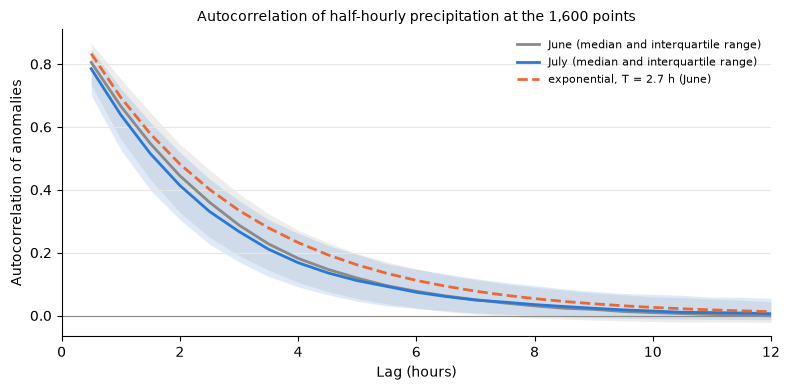

In [4]:
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a86", "#2b2b29"
fig, ax = plt.subplots(figsize=(8, 4))
hours = LAGS * 0.5
for rho, color, label in [(june_rho, GRAY, "June"), (july_rho, BLUE, "July")]:
    ax.fill_between(hours, *np.percentile(rho, [25, 75], axis=0), color=color, alpha=0.15, lw=0)
    ax.plot(hours, np.median(rho, axis=0), color=color, lw=2, label=f"{label} (median and interquartile range)")
scale = june_stats["decorrelation (h)"].median()
ax.plot(hours, np.exp(-hours / scale), color=ORANGE, lw=2, ls="--", label=f"exponential, T = {scale:.1f} h (June)")
ax.axhline(0, color=GRAY, lw=0.8)
ax.set(xlabel="Lag (hours)", ylabel="Autocorrelation of anomalies", xlim=(0, 12))
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(fontsize=8, frameon=False)
ax.set_title("Autocorrelation of half-hourly precipitation at the 1,600 points", fontsize=10)
fig.tight_layout()
plt.show()

The decorrelation time is stable between months: 2.7 hours in June and 2.9 hours in July (medians over the points), and the exponential of June's decorrelation time follows the measured autocorrelation, though precipitation decorrelates somewhat faster (an autocorrelation of 0.42 at 2 hours in July, against 0.48 for the exponential). The standard deviation is not stable at a point: June was wetter than July (a median of 1.12 against 0.87 mm/h), and the standard deviations of the points in the two months are hardly correlated (0.16), as each month's rain at a point is dominated by a few storms. Smoothing over neighboring points raises the correlation only to 0.21, but averages out much of the noise of a single month.

## Test 2: Sampling Errors

For each design, `estimate_sampling_error` predicts the error of each point's monthly mean from the times of its samples, with the statistics of June: the smoothed standard deviation of each point, and the median decorrelation time of the region. The predicted errors are standard deviations: if the model holds, the actual errors divided by the predicted ones (the standardized errors) have a root mean square of 1, and 95% of them are within 2. The table gives these, and the root mean square of the predicted and actual errors over the points. The figure compares them for groups of points with similar predicted errors (fifths of the points, by predicted error).

In [5]:
REGIONAL_DECORRELATION = timedelta(hours=float(june_stats["decorrelation (h)"].median()))


def evaluate(name, decorrelation_time, standard_deviation):
    """The predicted and actual errors of the monthly means of the points observed by a design."""
    predicted = estimate_sampling_error(
        observations[name], START, END, decorrelation_time, standard_deviation, targets=points
    ).set_index("target_hash")
    merged = actual[name].join(predicted[["sampling_error", "effective_samples"]])
    merged = merged[merged.samples > 0]
    merged["z"] = merged.error / merged.sampling_error
    return merged


def score(merged):
    """Summary statistics of predicted and actual errors."""
    return {
        "predicted RMS (mm/h)": np.sqrt((merged.sampling_error**2).mean()),
        "actual RMS (mm/h)": np.sqrt((merged.error**2).mean()),
        "RMS standardized error": np.sqrt((merged.z**2).mean()),
        "within 2 predicted (%)": 100 * (merged.z.abs() <= 2).mean(),
    }


held_out = {name: evaluate(name, REGIONAL_DECORRELATION, june_stats["smoothed sigma"]) for name in DESIGNS}
test2 = pd.DataFrame(
    {
        name: {"median samples": m.samples.median(), "median effective samples": m.effective_samples.median(), **score(m)}
        for name, m in held_out.items()
    }
).T
test2.round(3)

,median samples,median effective samples,predicted RMS (mm/h),actual RMS (mm/h),RMS standardized error,within 2 predicted (%)
GMI,22.0,21.790,0.251,0.219,1.030,95.250
one sun-synchronous,59.0,57.585,0.130,0.120,1.052,94.375
three sun-synchronous,176.0,110.840,0.053,0.045,1.017,94.438
GMI + three sun-synchronous,198.0,109.014,0.055,0.048,1.035,93.875


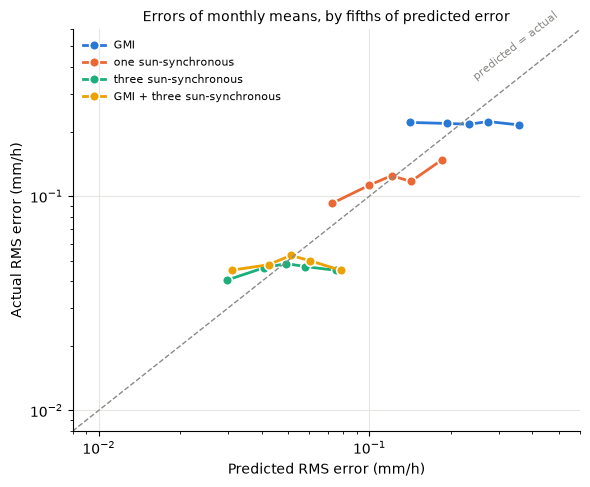

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
for (name, merged), color in zip(held_out.items(), (BLUE, ORANGE, AQUA, YELLOW)):
    groups = merged.groupby(pd.qcut(merged.sampling_error, 5), observed=True)
    predicted = groups.sampling_error.apply(lambda e: np.sqrt((e**2).mean()))
    measured = groups.error.apply(lambda e: np.sqrt((e**2).mean()))
    ax.plot(predicted, measured, marker="o", ms=7, mec="white", mew=1.2, color=color, lw=2, label=name)
limits = (0.008, 0.6)
ax.plot(limits, limits, color=GRAY, lw=1, ls="--")
ax.annotate("predicted = actual", (0.3, 0.3), xytext=(-20, 10), textcoords="offset points", fontsize=8, color=GRAY, rotation=38)
ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits, xlabel="Predicted RMS error (mm/h)", ylabel="Actual RMS error (mm/h)")
ax.grid(color="#e6e6e3", lw=0.8, which="major")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.set_title("Errors of monthly means, by fifths of predicted error", fontsize=10)
fig.tight_layout()
plt.show()

With the statistics of June, the predicted errors of July's monthly means hold for every design: the root mean square of the standardized errors is 1.02 to 1.05, and 94 to 95% of the errors are within 2 predicted standard deviations (95% for a normal distribution). The predictions are 8 to 18% larger than the actual errors on average over the points, as June was wetter than July, which a study can only know from climatology.

The figure shows that the predictions rank the designs correctly, by an order of magnitude from GMI alone (22 samples a month, an error of 0.22 mm/h) to three sun-synchronous satellites (176 samples, 0.045 mm/h), and capture a design's error to within its spread. Within a design, the predictions distinguish points less well: the actual errors of GMI's points hardly differ between the groups whose predicted errors differ by a factor of 2.5, as the differences between the standard deviations of the points in June do not persist in July. The model also predicts, and the samples confirm, that adding GMI to the three sun-synchronous satellites slightly increases the error of a simple mean of the samples (0.048 against 0.045 mm/h): GMI's samples add little independent information, and they weight the times of its passes more than a mean of the field does.

## Test 3: Model Inputs

The predictions depend on the statistics of the field. The table gives the root mean square of the standardized errors of each design for other inputs: the statistics of each point in June (rather than smoothed or regional), one regional standard deviation, the statistics of July itself (which a study would not have), and samples taken as independent (a decorrelation time of a second, for which the error is the familiar `sigma / sqrt(n)`).

In [7]:
variants = {
    "June, smoothed sigma (Test 2)": (REGIONAL_DECORRELATION, june_stats["smoothed sigma"]),
    "June, each point's sigma and decorrelation": (
        pd.to_timedelta(june_stats["decorrelation (h)"].fillna(june_stats["decorrelation (h)"].median()), unit="h"),
        june_stats.sigma,
    ),
    "June, regional sigma": (REGIONAL_DECORRELATION, float(june_stats.sigma.median())),
    "July, each point's sigma and decorrelation": (
        pd.to_timedelta(july_stats["decorrelation (h)"].fillna(july_stats["decorrelation (h)"].median()), unit="h"),
        july_stats.sigma,
    ),
    "independent samples (June, smoothed sigma)": (timedelta(seconds=1), june_stats["smoothed sigma"]),
}
test3 = pd.DataFrame(
    {
        variant: {name: score(evaluate(name, scale, sigma))["RMS standardized error"] for name in DESIGNS}
        for variant, (scale, sigma) in variants.items()
    }
)
test3.round(2)

,"June, smoothed sigma (Test 2)","June, each point's sigma and decorrelation","June, regional sigma","July, each point's sigma and decorrelation","independent samples (June, smoothed sigma)"
GMI,1.03,1.19,1.00,1.01,0.95
one sun-synchronous,1.05,1.29,1.07,1.12,0.81
three sun-synchronous,1.02,1.21,0.99,1.07,0.55
GMI + three sun-synchronous,1.04,1.23,1.01,1.08,0.62


The inputs matter more than the details of the model. Each point's own standard deviation from June gives standardized errors of 1.19 to 1.29: the predictions are right on average but wrong at individual points, by the noise of a single month's statistics. One regional standard deviation, or the smoothed standard deviations of Test 2, give 0.99 to 1.07, as does each point's statistics from July itself (1.01 to 1.12), which a study would not have.

Taking samples as independent (the error of a mean of `n` independent samples, `sigma / sqrt(n)`) is adequate for sparse sampling (0.95 for GMI's 22 samples a month) but overpredicts the errors of dense sampling by up to 1.8 times (0.55 for the three sun-synchronous satellites): samples within a few hours of each other repeat each other, but they also share their variations with the monthly mean that they estimate, which the exponential correlation model accounts for.

## Test 4: Daily Cycle

The model's field is stationary: it has no daily cycle. Sun-synchronous satellites observe each point at nearly the same local times every day, so where precipitation has a strong daily cycle, their samples repeat the same phase of it, and the error of the mean has a systematic part (a bias) that the model does not predict. The daily cycle of each point is its mean precipitation in each 3-hour interval of local (mean solar) time in July, and its strength is the range of these means relative to the monthly mean. The table gives, for thirds of the points by the strength of their daily cycle, the root mean square of the standardized errors of each design (as in Test 2), and the mean error of the single sun-synchronous design relative to the mean precipitation.

In [8]:
series = july.values.reshape(july.sizes["time"], -1).T
utc_hours = july.time.dt.hour.values + july.time.dt.minute.values / 60
local_bin = (((utc_hours[None, :] + points.geometry.x.values[:, None] / 15) % 24) // 3).astype(int)
cycle = np.array([[series[i, local_bin[i] == b].mean() for b in range(8)] for i in range(len(points))])
strength = pd.Series((cycle.max(axis=1) - cycle.min(axis=1)) / series.mean(axis=1), index=points.target_hash)
band = pd.qcut(strength, 3, labels=["weak", "moderate", "strong"])
test4 = pd.DataFrame(
    {
        name: merged.groupby(band.reindex(merged.index), observed=True).z.apply(lambda z: np.sqrt((z**2).mean()))
        for name, merged in held_out.items()
    }
)
single = held_out["one sun-synchronous"]
test4["one sun-synchronous: mean error (% of mean)"] = single.groupby(band.reindex(single.index), observed=True).apply(
    lambda g: 100 * g.error.mean() / g.true_mean.mean()
)
test4.insert(0, "daily range / mean (median)", strength.groupby(band, observed=True).median())
test4.round(2)

,daily range / mean (median),GMI,one sun-synchronous,three sun-synchronous,GMI + three sun-synchronous,one sun-synchronous: mean error (% of mean)
weak,1.38,1.05,0.91,1.06,1.08,3.39
moderate,2.02,0.85,0.96,0.93,0.91,1.80
strong,2.92,1.16,1.25,1.05,1.11,2.99


The daily cycle is the main limit of the model. At the third of the points with the strongest daily cycles (whose 3-hourly means range over about 3 times the monthly mean), the errors of the single sun-synchronous satellite are 25% larger than predicted (1.25), and those of GMI 16% larger, whereas they are within 15% of the predictions at the other points. The satellites that sample more local times are less affected (1.05 for three sun-synchronous satellites). The single sun-synchronous satellite also overestimates the monthly means by 2 to 3% (a bias at its local times of 13:30 and 01:30), small next to its random error here (60% of the mean). A study of a design that samples a strongly cycling field at few local times should expect errors somewhat larger than predicted.

## Summary

| Test | Metric | Result |
|---|---|---|
| Field statistics | Decorrelation time (median, June and July) | 2.7 and 2.9 h |
| | Correlation of standard deviations of June and July at the points (each point, smoothed) | 0.16, 0.21 |
| Sampling errors (June statistics) | RMS standardized error of July's monthly means | 1.02 to 1.05 (four designs) |
| | Errors within 2 predicted standard deviations | 94 to 95% |
| | Errors of designs (actual RMS) | 0.22 mm/h (GMI, 22 samples a month) to 0.045 mm/h (three sun-synchronous, 176 samples), ranked as predicted |
| Model inputs | RMS standardized error: each point's June statistics; regional; July's | 1.19 to 1.29; 0.99 to 1.07; 1.01 to 1.12 |
| | Independent samples (`sigma / sqrt(n)`) | 0.55 to 0.95 (overpredicts dense sampling by up to 1.8 times) |
| Daily cycle | RMS standardized error at the strongest third of daily cycles | 1.25 (one sun-synchronous), 1.16 (GMI), 1.05 (three) |
| | Bias of one sun-synchronous satellite | +2 to +3% of the mean |

TAT-C's sampling error model predicts the errors of monthly mean precipitation from real constellations' samples, given a standard deviation from another month (smoothed over neighboring points or regional) and a regional decorrelation time. Use smoothed or climatological standard deviations rather than a single month's at each point, and expect errors up to 25% larger than predicted where the field's daily cycle is strong and the design samples few local times.

Limitations:

* **One region and month.** The Maritime Continent in July, with convective precipitation and strong daily cycles; other fields (such as temperature) and seasons have other statistics.
* **IMERG as the truth.** IMERG's half-hourly values merge the observations of the same kinds of satellites, interpolated between them by the motion of the precipitation, which may smooth its variations within hours and lengthen its decorrelation time.
* **Temporal sampling only.** Each sample is the value of a 0.1 deg cell in its half-hour: the footprints of the instruments, the times within the half-hour, and the errors of the retrievals are not modeled.